In [1]:
import numpy as np
import matplotlib.pyplot as plt

In [2]:
class Source:
    "Источник изотропного излучения фотонов"
    def __init__(self, Y: float = 10000):
        self.Y = Y

    def random_direction(self, E: float) ->np.ndarray:
        """Розыгрыш начального направления"""
        if E < 0:
            raise ValueError("Энергия может быть отрицательной")

        N = int(round(self.Y * E))

        phi = np.random.uniform(0, 2*np.pi, N)
        cosTheta = np.random.uniform(-1, 1, N)
        sinTheta = np.sqrt(1 - cosTheta**2)
        return np.array([sinTheta*np.cos(phi),
                         sinTheta*np.sin(phi),
                         cosTheta])

In [ ]:
class Detector:
    "Сферический детектор "

    def __init__(self, R=2.0, N=40, r=0.1, a=0.5):
        self.R = R
        self.N = N
        self.r = r
        self.a = a

        self.p_positions = self.generate_positions()

    def generate_positions(self) -> np.ndarray:
        "Размещение ФЭУ"

        i = np.arange(self.N)
        z = self.R * (1 - 2 * (i + 0.5) / self.N)
        phi = i * np.pi * (3 - np.sqrt(5))
        rho = np.sqrt(self.R**2 - z**2)

        x = rho * np.cos(phi)
        y = rho * np.sin(phi)

        return np.column_stack((x, y, z))

    def is_on_pmt(self, point) -> bool:
        "Проверка принадлежности точки одному из ФЭУ "

        point = np.asarray(point)

        if not np.isclose(np.linalg.norm(point), self.R):
            return False

        distances = np.linalg.norm(
            self.p_positions - point, axis=1
        )

        return bool(np.any(distances <= self.r))

    def intersection(self, position, directions) -> np.ndarray:
        "Точки пересечения фотонов со сферой "
        position = np.asarray(position, dtype= float)

        if np.linalg.norm(position) >= self.R:
            return None

        b = position @ directions

        # Расстояния до поверхности детектора
        t = -b + np.sqrt(b**2 + self.R**2 - np.dot(position, position))

        # Все точки пересечения
        return position[:, None] + directions * t[None, :]

    def photon_hits(self, points) -> np.ndarray:
        "Определяет, в какой фотоумножитель попадёт фотон "
        distances2 = np.sum(
            (points.T[:, None, :] -
             self.p_positions[None, :, :])**2,
            axis=2
        )

        # Ближайший фотоумножитель к каждому фотону
        nearest = np.argmin(distances2, axis=1)

        hits = distances2[
            np.arange(points.shape[1]), nearest
        ] <= self.r**2

        return np.bincount(
            nearest[hits], minlength=self.N
        )

    def photoelectrons(self, n_photons=1):
        "Возвращает случайное число фотоэлектронов по распределению Пуассона со средним a "

        return np.random.poisson(self.a * n_photons)


In [4]:

np.random.seed(42)

source = Source(Y=10000)
detector = Detector(R=2.0, N=40, r=0.1, a=0.5)

E = 1.0
position = np.array([0.0, 0.0, 0.0])


In [5]:
directions = source.random_direction(E)

# Распространение до поверхности детектора
points = detector.intersection(position, directions)

n_hits = detector.photon_hits(points)

# Генерация зарегистрированных фотоэлектронов
n_pe = detector.photoelectrons(n_hits)

Q = np.sum(n_pe)

In [ ]:
print("Число испущенных фотонов:", directions.shape[1])
print("Попало на ФЭУ:", np.sum(n_hits))
print("Полный собранный заряд:", Q)

Испущено фотонов: 10000
Попало на ФЭУ: 239
Полный собранный заряд: 115


In [8]:
# Все фотоны должны достичь сферы
assert np.allclose(
    np.linalg.norm(points, axis=0),
    detector.R
)

# Количество зарегистрированных фотонов
# не может превышать количество испущенных
assert np.sum(n_hits) <= directions.shape[1]

# Все количества фотоэлектронов неотрицательны
assert np.all(n_pe >= 0)


In [9]:

Q_expected_task = (
    detector.a * source.Y *
    detector.N * detector.r**2 / detector.R**2
)

Q_expected_sphere = Q_expected_task / 4


In [10]:
print(f"Монте-Карло: {Q} фотоэлектронов")
print(f"Формула задания: {Q_expected_task:.1f}")
print(f"Ожидание для сферы: {Q_expected_sphere:.1f}")
print(
    "Отклонение от сферического ожидания:",
    f"{abs(Q - Q_expected_sphere) / Q_expected_sphere * 100:.1f}%"
)

Монте-Карло: 115 фотоэлектронов
Формула задания: 500.0
Ожидание для сферы: 125.0
Отклонение от сферического ожидания: 8.0%


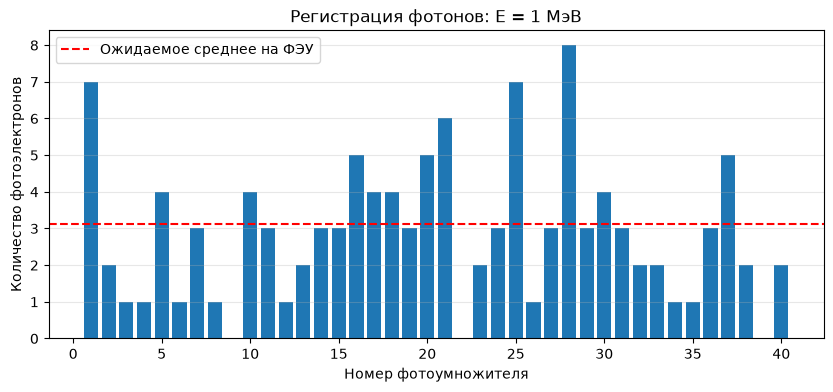

In [11]:
plt.figure(figsize=(10, 4))

plt.bar(
    np.arange(1, detector.N + 1),
    n_pe
)

plt.axhline(
    Q_expected_sphere / detector.N,
    color="red",
    linestyle="--",
    label="Ожидаемое среднее на ФЭУ"
)

plt.xlabel("Номер фотоумножителя")
plt.ylabel("Количество фотоэлектронов")
plt.title("Регистрация фотонов: E = 1 МэВ")
plt.legend()
plt.grid(axis="y", alpha=0.3)
plt.show()